# Generate BDDL problems for `camera_relocalization`

Generate one `camera_relocalization` BDDL problem per **reachable room type** for a
BEHAVIOR-1K scene.

**Pipeline**
1. Load the scene's **no-door traversability map** (`floor_trav_no_door_0.png`) and
   its **room semantic-segmentation map** (`floor_semseg_0.png`).
2. Black out pixels with no room label (`floor_semseg_0 == 0`) from the
   traversability map, then **erode** the remaining free-space by the robot
   footprint and compute the **connected components** of what survives. The erosion mirrors OmniGibson's
   `TraversableMap._erode_trav_map`: radius `= ||chassis_extent_xy|| / 2 + 0.2`,
   applied with a **square** structuring element of side
   `radius_pixel = ceil(radius / resolution)`. For **r1pro** this is `0.9544 m -> 96 px`.
3. For every connected component, find the **union of room types** it covers
   (a component may span several rooms, e.g. `living_room` + `corridor`).
4. For each reachable room type **not already registered**, write a new
   `problem_i.bddl` and record it in **`mappings.json`**
   (`index -> {"inroom": room_type, "non-robot-tros": ""}`). Room types that already
   have a problem file are **skipped, not duplicated or deleted** -- so the registry
   accumulates across scenes/re-runs.

Floor-plan images are stored at **0.01 m / pixel**. Robot chassis XY extents are read
from `robot_chassis_extents.json` (precomputed offline by `compute_chassis_extents.py`;
this notebook does **not** launch Isaac Sim).

> Run this notebook with the **`ispatialgym`** conda env (`cv2`, `numpy`, `matplotlib`).

In [56]:
%matplotlib inline
import json
import math
import re
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

In [57]:
# ---------------------------------------------------------------------------
# Configuration  (edit SCENE_NAME / ROBOT_MODEL to retarget)
# ---------------------------------------------------------------------------
SCENE_NAME  = "office_cubicles_right"
ROBOT_MODEL = "r1pro"

REPO_ROOT    = Path("/home/minyeongk/Desktop/projects/ispatialgym")
DATASET_ROOT = REPO_ROOT / "Behavior-1K/datasets/behavior-1k-assets"
LAYOUT_DIR   = DATASET_ROOT / "scenes" / SCENE_NAME / "layout"

TRAV_MAP_PATH   = LAYOUT_DIR / "floor_trav_no_door_0.png"   # no-door traversability map
SEMSEG_MAP_PATH = LAYOUT_DIR / "floor_semseg_0.png"         # room semantic-segmentation map

# BEHAVIOR-1K floor-plan images are stored at 0.01 m / pixel.
MAP_RESOLUTION = 0.01            # meters per pixel

# Robot footprint -> erosion radius. By default it is derived from the robot's
# chassis AABB (OmniGibson formula); set the override to force a fixed radius.
CHASSIS_EXTENTS_PATH = Path(
    "/home/minyeongk/Desktop/projects/BEHAVIOR-1K-ORIGIN/datasets/"
    "2026-challenge-task-instances-raw-demo/robot_chassis_extents.json"
)
# Fallback used only if the JSON above is missing (last-known value from it).
FALLBACK_CHASSIS_EXTENTS = {"r1pro": [0.8164507150650024, 1.2687956094741821]}
# Set to a float (meters) to bypass the chassis derivation; None = derive it.
EROSION_RADIUS_M_OVERRIDE = 0.47

# Connected-component connectivity (OmniGibson traversability uses 4-connectivity).
CONNECTIVITY = 4

# Components smaller than this are treated as erosion noise and ignored.
MIN_COMPONENT_AREA_M2 = 0.01     # ~ a 10 cm x 10 cm patch

# Downsample large floor-plan images for matplotlib only. All computation below
# still uses the full-resolution maps.
MAX_VIS_SIDE_PX = 2000

# Output: one problem_*.bddl per reachable room type, indexed by mappings.json.
ACTIVITY_NAME = "camera_relocalization"
OUTPUT_DIR = REPO_ROOT / "ispatialgym/assets/bddl/activity_definitions" / ACTIVITY_NAME
MAPPINGS_PATH = OUTPUT_DIR / "mappings.json"

# Canonical room-id -> room-name table (semseg pixel value v maps to line v).
ROOM_CATEGORIES_CANDIDATES = [
    DATASET_ROOT / "metadata" / "room_categories.txt",
    REPO_ROOT / "Behavior-1K/datasets/behavior-1k-assets-outdated/metadata/room_categories.txt",
]

print(f"Scene:                 {SCENE_NAME}")
print(f"Robot:                 {ROBOT_MODEL}")
print(f"Map resolution:        {MAP_RESOLUTION} m/px")
print(f"CC connectivity:       {CONNECTIVITY}")
print(f"Min component area:    {MIN_COMPONENT_AREA_M2} m^2")
print(f"Output bddl directory: {OUTPUT_DIR}")

Scene:                 office_cubicles_right
Robot:                 r1pro
Map resolution:        0.01 m/px
CC connectivity:       4
Min component area:    0.01 m^2
Output bddl directory: /home/minyeongk/Desktop/projects/ispatialgym/ispatialgym/assets/bddl/activity_definitions/camera_relocalization


In [58]:
# Resolve the room-category table (semseg id -> room-type name).
room_categories_path = next((p for p in ROOM_CATEGORIES_CANDIDATES if p.exists()), None)
assert room_categories_path is not None, "Could not find room_categories.txt"
with open(room_categories_path) as f:
    ROOM_CATEGORIES = [line.rstrip("\n") for line in f]

def room_id_to_name(room_id: int) -> str:
    """Map a floor_semseg pixel value to its room-type name (table is 1-indexed)."""
    return ROOM_CATEGORIES[room_id - 1]

print(f"Loaded {len(ROOM_CATEGORIES)} room categories from:\n  {room_categories_path}")

Loaded 39 room categories from:
  /home/minyeongk/Desktop/projects/ispatialgym/Behavior-1K/datasets/behavior-1k-assets/metadata/room_categories.txt


In [59]:
# Erosion radius from the robot chassis AABB, mirroring OmniGibson's
# TraversableMap._erode_trav_map:
#     radius_m     = ||chassis_extent_xy|| / 2 + 0.2
#     radius_pixel = ceil(radius_m / map_resolution)
# (chassis_extent_xy == robot.reset_joint_pos_aabb_extent[:2], precomputed offline
# and stored in robot_chassis_extents.json by compute_chassis_extents.py).
if EROSION_RADIUS_M_OVERRIDE is not None:
    erosion_radius_m = float(EROSION_RADIUS_M_OVERRIDE)
    chassis_extent_xy = None
    radius_source = "manual override"
else:
    if CHASSIS_EXTENTS_PATH.exists():
        chassis_extents = json.loads(CHASSIS_EXTENTS_PATH.read_text())
    else:
        chassis_extents = FALLBACK_CHASSIS_EXTENTS
        print(f"[warn] {CHASSIS_EXTENTS_PATH} not found; using built-in fallback extents.")
    assert ROBOT_MODEL in chassis_extents, (
        f"No chassis extent for {ROBOT_MODEL!r}. Have: {sorted(chassis_extents)}. "
        f"Run compute_chassis_extents.py for this robot first."
    )
    chassis_extent_xy = np.asarray(chassis_extents[ROBOT_MODEL], dtype=float)
    erosion_radius_m = float(np.linalg.norm(chassis_extent_xy) / 2.0 + 0.2)
    radius_source = f"{ROBOT_MODEL} chassis AABB {chassis_extent_xy.tolist()}"

radius_pixel = int(math.ceil(erosion_radius_m / MAP_RESOLUTION))
print(f"Erosion radius source: {radius_source}")
print(f"Erosion radius:        {erosion_radius_m:.4f} m  ->  {radius_pixel} px "
      f"(square kernel {radius_pixel}x{radius_pixel}) @ {MAP_RESOLUTION} m/px")

Erosion radius source: manual override
Erosion radius:        0.4700 m  ->  47 px (square kernel 47x47) @ 0.01 m/px


Map shape: (4184, 4184)  (41.84 m x 41.84 m)
Blacked-out no-room free pixels:  3841177  ( 384.12 m^2)
Visualization downsample: every 3 px
Room types present in segmentation map:
  id   2 -> bathroom
  id   9 -> conference_hall
  id  10 -> copy_room
  id  11 -> corridor
  id  13 -> empty_room
  id  19 -> lobby
  id  21 -> meeting_room
  id  23 -> private_office
  id  25 -> shared_office


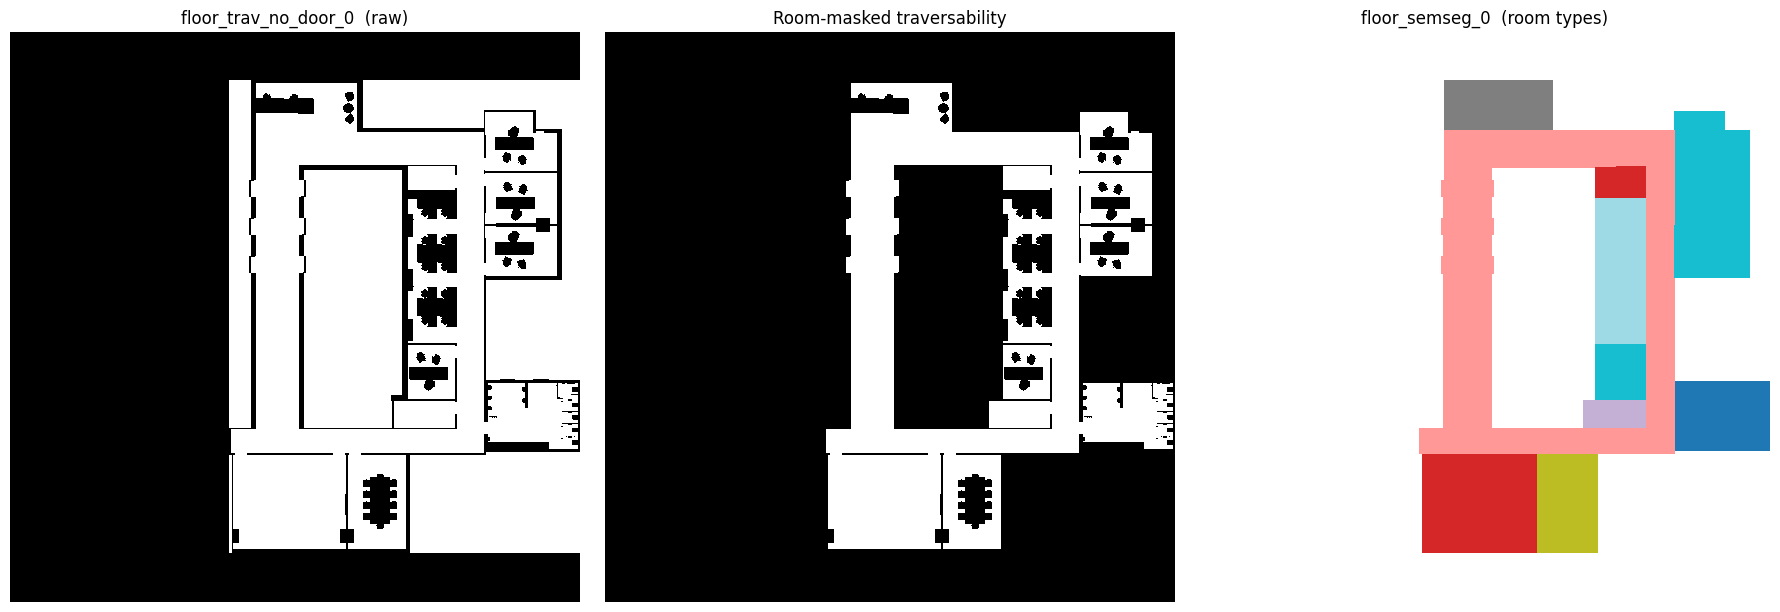

In [60]:
# Load the no-door traversability map and the room semantic-segmentation map.
trav_img   = cv2.imread(str(TRAV_MAP_PATH), cv2.IMREAD_GRAYSCALE)
semseg_img = cv2.imread(str(SEMSEG_MAP_PATH), cv2.IMREAD_GRAYSCALE)
assert trav_img is not None,   f"Missing {TRAV_MAP_PATH}"
assert semseg_img is not None, f"Missing {SEMSEG_MAP_PATH}"
assert trav_img.shape == semseg_img.shape, "trav and semseg maps must be pixel-aligned"

# Black out traversability pixels that are not assigned to a room in the semseg map.
room_mask = semseg_img > 0
trav_room_img = trav_img.copy()
trav_room_img[~room_mask] = 0
no_room_free_px = int(((trav_img == 255) & ~room_mask).sum())

# Binary free-space mask after room masking (the no-door map is already {0, 255}).
free_mask = (trav_room_img == 255).astype(np.uint8)

# Room types actually present in this scene's segmentation map.
scene_room_ids = sorted(set(np.unique(semseg_img).tolist()) - {0})
h, w = trav_img.shape
print(f"Map shape: {trav_img.shape}  "
      f"({w * MAP_RESOLUTION:.2f} m x {h * MAP_RESOLUTION:.2f} m)")
print(f"Blacked-out no-room free pixels: {no_room_free_px:>8d}  "
      f"({no_room_free_px * MAP_RESOLUTION ** 2:7.2f} m^2)")
vis_stride = max(1, int(math.ceil(max(h, w) / MAX_VIS_SIDE_PX)))
vis_slice = np.s_[::vis_stride, ::vis_stride]
if vis_stride > 1:
    print(f"Visualization downsample: every {vis_stride} px")
print("Room types present in segmentation map:")
for rid in scene_room_ids:
    print(f"  id {rid:3d} -> {room_id_to_name(rid)}")

semseg_vis = semseg_img[vis_slice]
semseg_vis = np.ma.masked_where(semseg_vis == 0, semseg_vis)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(trav_img[vis_slice], cmap="gray", interpolation="nearest")
ax[0].set_title("floor_trav_no_door_0  (raw)")
ax[1].imshow(trav_room_img[vis_slice], cmap="gray", interpolation="nearest")
ax[1].set_title("Room-masked traversability")
ax[2].imshow(semseg_vis, cmap="tab20", interpolation="nearest")
ax[2].set_title("floor_semseg_0  (room types)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

Free-space pixels:         3922999  ( 392.30 m^2)
Eroded free-space pixels:  2809359  ( 280.94 m^2)


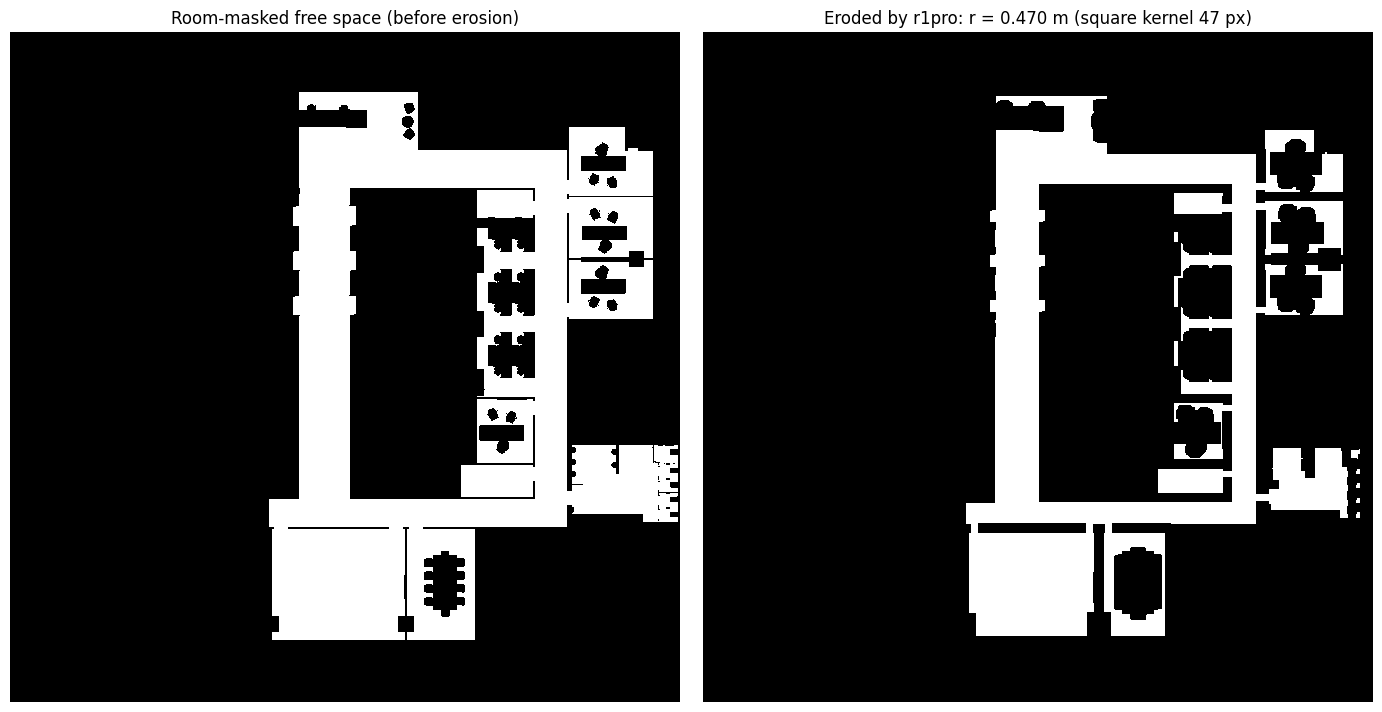

In [61]:
# Erode the free-space by the robot footprint, mirroring OmniGibson's
# TraversableMap._erode_trav_map exactly: a *square* structuring element of side
# `radius_pixel` (np.ones((radius_pixel, radius_pixel))). The eroded mask = the
# set of valid robot-center pixels.
kernel = np.ones((radius_pixel, radius_pixel), dtype=np.uint8)
eroded_mask = cv2.erode(free_mask, kernel)

print(f"Free-space pixels:        {int(free_mask.sum()):>8d}  "
      f"({free_mask.sum() * MAP_RESOLUTION ** 2:7.2f} m^2)")
print(f"Eroded free-space pixels: {int(eroded_mask.sum()):>8d}  "
      f"({eroded_mask.sum() * MAP_RESOLUTION ** 2:7.2f} m^2)")

vis_stride = max(1, int(math.ceil(max(free_mask.shape) / MAX_VIS_SIDE_PX)))
vis_slice = np.s_[::vis_stride, ::vis_stride]

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(free_mask[vis_slice], cmap="gray", interpolation="nearest")
ax[0].set_title("Room-masked free space (before erosion)")
ax[1].imshow(eroded_mask[vis_slice], cmap="gray", interpolation="nearest")
ax[1].set_title(f"Eroded by {ROBOT_MODEL}: r = {erosion_radius_m:.3f} m "
                f"(square kernel {radius_pixel} px)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

Found 8 connected component(s) in the eroded free-space.


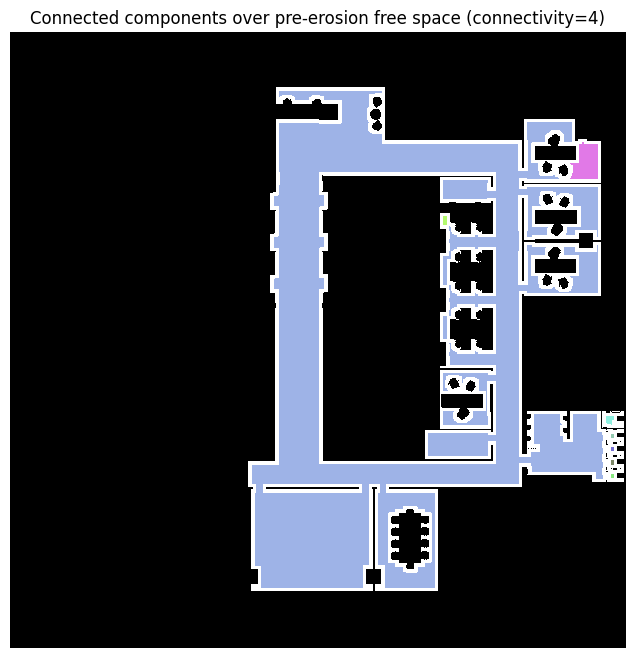

In [62]:
# Connected components of the eroded free-space (label 0 is background).
num_labels, labels = cv2.connectedComponents(eroded_mask, connectivity=CONNECTIVITY)
num_components = num_labels - 1
print(f"Found {num_components} connected component(s) in the eroded free-space.")

# Colorize the components over the pre-erosion free-space map.
rng = np.random.default_rng(0)
palette = np.vstack([
    np.zeros((1, 3), dtype=np.uint8),
    rng.integers(50, 256, size=(max(num_labels - 1, 0), 3), dtype=np.uint8),
])
vis_stride = max(1, int(math.ceil(max(labels.shape) / MAX_VIS_SIDE_PX)))
vis_slice = np.s_[::vis_stride, ::vis_stride]
labels_vis = labels[vis_slice]
base_vis = free_mask[vis_slice]
cc_rgba = np.zeros((*labels_vis.shape, 4), dtype=np.float32)
cc_rgba[..., :3] = palette[labels_vis] / 255.0
cc_rgba[..., 3] = (labels_vis > 0) * 0.75

plt.figure(figsize=(8, 8))
plt.imshow(base_vis, cmap="gray", interpolation="nearest")
plt.imshow(cc_rgba, interpolation="nearest")
plt.title(f"Connected components over pre-erosion free space (connectivity={CONNECTIVITY})")
plt.axis("off")
plt.show()

 CC  area (m^2)   kept  room types
--------------------------------------------------------
  1      276.70    yes  bathroom, conference_hall, copy_room, corridor, empty_room, lobby, meeting_room, private_office, shared_office
  2        3.57    yes  private_office
  3        0.15    yes  shared_office
  4        0.27    yes  bathroom
  5        0.06    yes  bathroom
  6        0.06    yes  bathroom
  7        0.06    yes  bathroom
  8        0.06    yes  bathroom


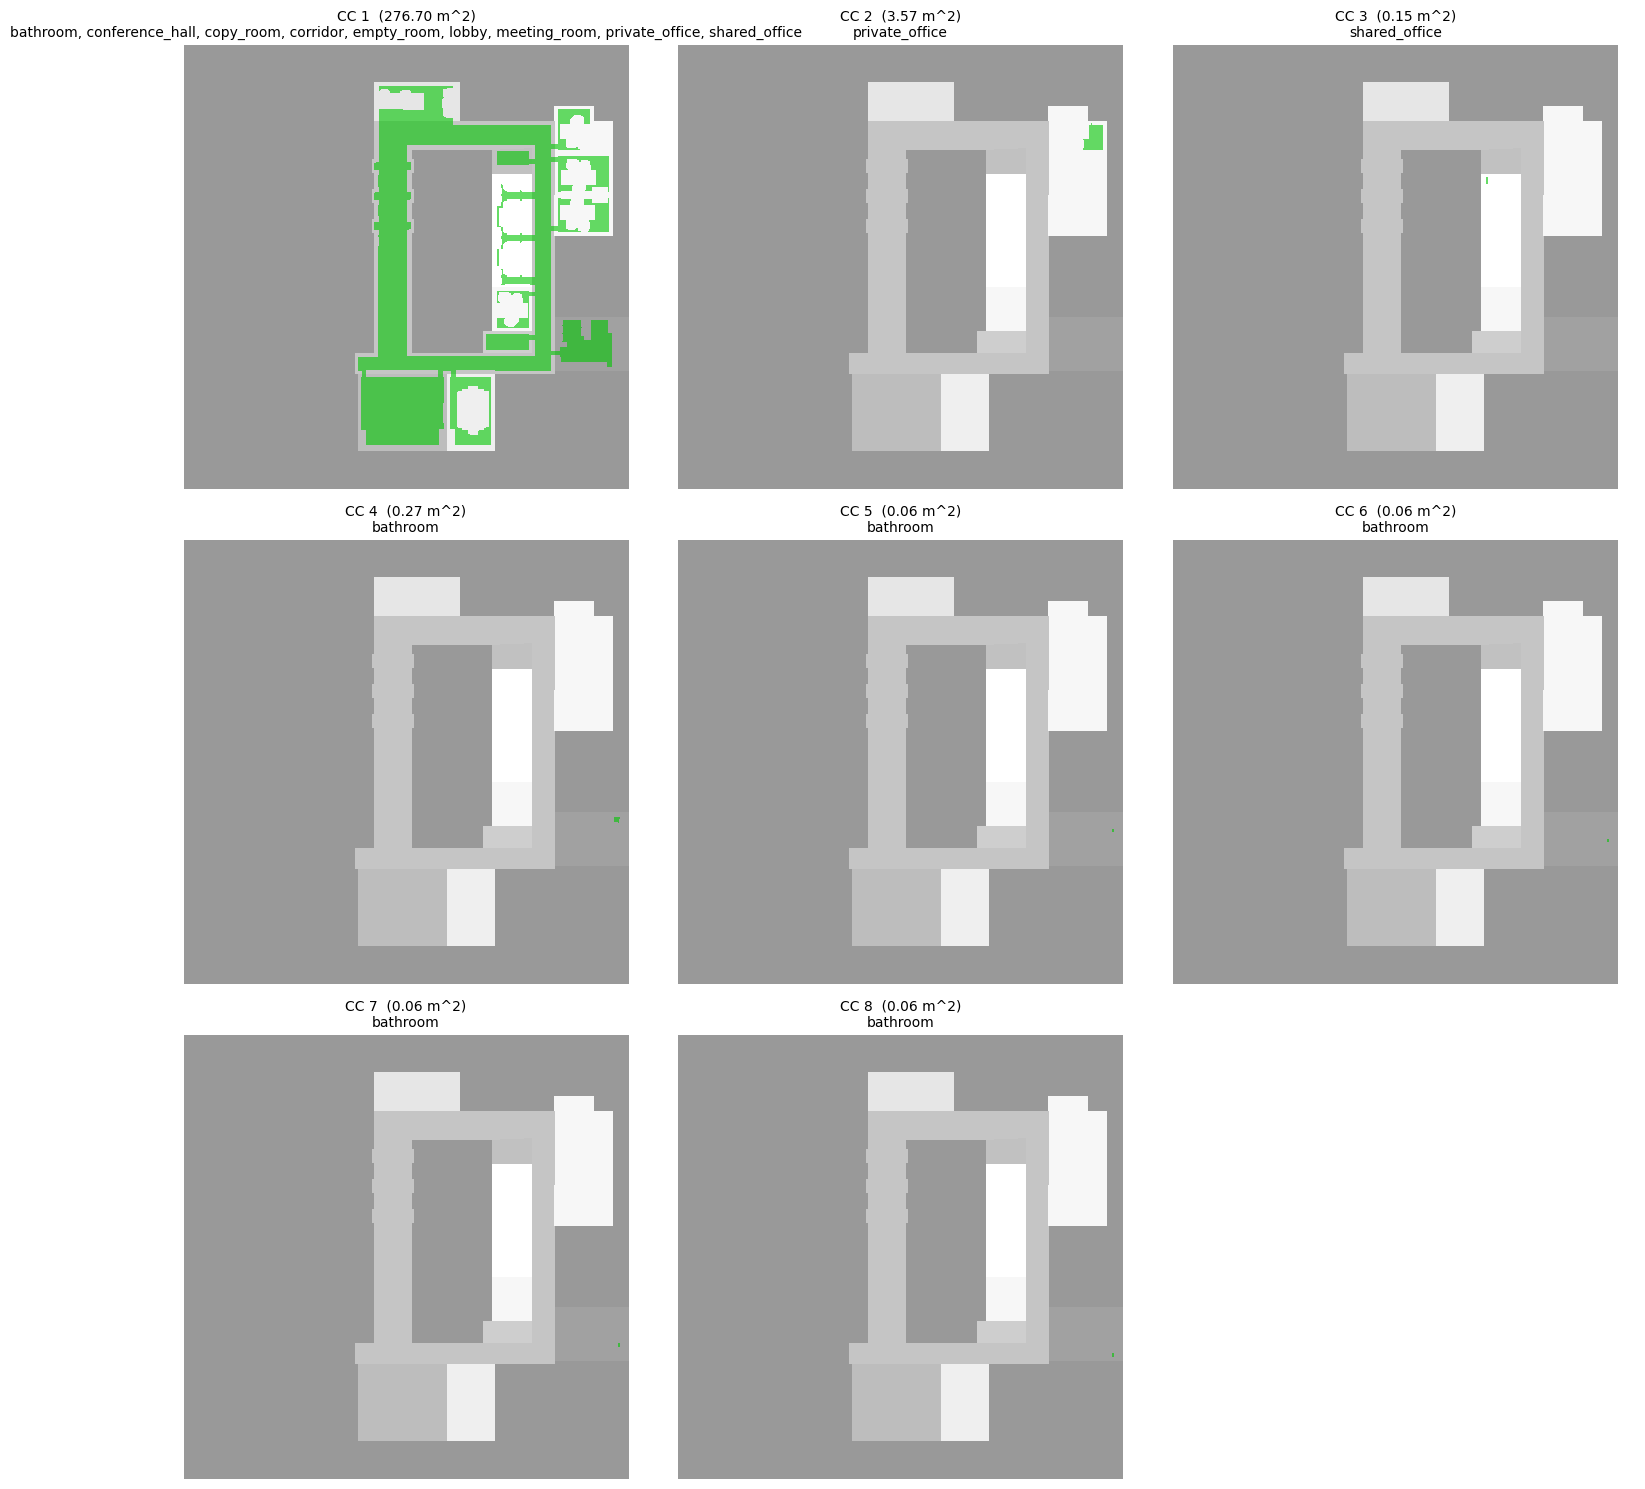

In [63]:
# For each connected component, compute its area and the union of room types it
# covers (via the segmentation map). Components below MIN_COMPONENT_AREA_M2 are
# flagged as erosion noise and excluded from the reachable-room-type union.
px_to_m2 = MAP_RESOLUTION ** 2
min_area_px = MIN_COMPONENT_AREA_M2 / px_to_m2

components = []
for lab in range(1, num_labels):
    mask = labels == lab
    area_px = int(mask.sum())
    room_ids = sorted(set(np.unique(semseg_img[mask]).tolist()) - {0})
    room_types = sorted(room_id_to_name(r) for r in room_ids)
    ys, xs = np.where(mask)
    components.append({
        "label": lab,
        "area_px": area_px,
        "area_m2": area_px * px_to_m2,
        "room_types": room_types,
        "centroid": (int(xs.mean()), int(ys.mean())),
        "kept": area_px >= min_area_px,
    })

print(f"{'CC':>3}  {'area (m^2)':>10}  {'kept':>5}  room types")
print("-" * 56)
for c in components:
    print(f"{c['label']:>3}  {c['area_m2']:>10.2f}  {('yes' if c['kept'] else 'NO'):>5}  "
          f"{', '.join(c['room_types']) or '(none)'}")

# Visualize each component on top of the segmentation map, titled with its rooms.
vis_stride = max(1, int(math.ceil(max(labels.shape) / MAX_VIS_SIDE_PX)))
vis_slice = np.s_[::vis_stride, ::vis_stride]
labels_vis = labels[vis_slice]
semseg_vis = semseg_img[vis_slice]
ncols = 3
nrows = max(1, int(np.ceil(num_components / ncols)))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, components):
    overlay = np.zeros((*labels_vis.shape, 4), dtype=np.float32)
    comp_vis = labels_vis == c["label"]
    overlay[comp_vis, :3] = (0.0, 0.78, 0.0) if c["kept"] else (0.78, 0.0, 0.0)
    overlay[comp_vis, 3] = 0.6
    ax.imshow(semseg_vis, cmap="gray", alpha=0.4, interpolation="nearest")
    ax.imshow(overlay, interpolation="nearest")
    title = f"CC {c['label']}  ({c['area_m2']:.2f} m^2)\n{', '.join(c['room_types']) or '(none)'}"
    if not c["kept"]:
        title += "  [dropped]"
    ax.set_title(title, fontsize=10)
    ax.axis("off")
for ax in axes[num_components:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [64]:
# Union of room types over all *kept* components = the room types the eroded
# robot footprint can actually occupy.
reachable_room_types = sorted({
    rt for c in components if c["kept"] for rt in c["room_types"]
})

dropped = [c["label"] for c in components if not c["kept"]]
if dropped:
    print(f"Ignored {len(dropped)} sub-threshold component(s): {dropped}")
print(f"\nReachable room types ({len(reachable_room_types)}):")
for i, rt in enumerate(reachable_room_types, start=1):
    print(f"  {i}. {rt}")


Reachable room types (9):
  1. bathroom
  2. conference_hall
  3. copy_room
  4. corridor
  5. empty_room
  6. lobby
  7. meeting_room
  8. private_office
  9. shared_office


In [65]:
# # Write one camera_relocalization problem per reachable room type, tracked in a
# # registry (mappings.json). Room types that already have a problem file are
# # skipped -- never duplicated, overwritten, or deleted -- so the registry
# # accumulates across re-runs and across scenes.
# BDDL_TEMPLATE = """(define (problem {activity}-{i})
#     (:domain behavior-1k)

#     (:objects
#         floor.n.01_1 - floor.n.01
#         agent.n.01_1 - agent.n.01
#     )

#     (:init
#         (inroom floor.n.01_1 {room_type})
#         (ontop agent.n.01_1 floor.n.01_1)
#         (pose_reached agent.n.01_1)
#     )

#     (:goal
#         (and
#             (pose_reached ?agent.n.01_1)
#             (pose_settled ?agent.n.01_1)
#         )
#     )
# )
# """

# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# # Load the existing registry: {problem_index -> {"inroom": room_type, "non-robot-tros": ...}}.
# mappings = json.loads(MAPPINGS_PATH.read_text()) if MAPPINGS_PATH.exists() else {}

# # Reconcile any problem_*.bddl already on disk but missing from the registry, so a
# # room type that already has a file is never duplicated.
# INROOM_RE = re.compile(r"\(inroom\s+floor\.n\.01_1\s+([^\s)]+)\)")
# for bddl in sorted(OUTPUT_DIR.glob("problem_*.bddl")):
#     idx = bddl.stem.split("_", 1)[1]
#     if not idx.isdigit() or idx in mappings:
#         continue
#     m = INROOM_RE.search(bddl.read_text())
#     if m:
#         mappings[idx] = {"inroom": m.group(1), "non-robot-tro": ""}

# room_type_to_index = {entry["inroom"]: idx for idx, entry in mappings.items()}
# next_index = max((int(idx) for idx in mappings), default=0) + 1

# created = []
# for room_type in reachable_room_types:
#     if room_type in room_type_to_index:
#         print(f"problem_{room_type_to_index[room_type]}.bddl already exists for "
#               f"room type '{room_type}' -- skipping")
#         continue
#     idx = next_index
#     next_index += 1
#     out_path = OUTPUT_DIR / f"problem_{idx}.bddl"
#     out_path.write_text(BDDL_TEMPLATE.format(activity=ACTIVITY_NAME, i=idx, room_type=room_type))
#     mappings[str(idx)] = {"inroom": room_type, "non-robot-tros": ""}
#     room_type_to_index[room_type] = str(idx)
#     created.append(out_path)
#     print(f"[+] wrote problem_{idx}.bddl  (inroom {room_type})")

# # Persist the registry, ordered by integer index.
# mappings = {str(i): mappings[str(i)] for i in sorted(int(k) for k in mappings)}
# MAPPINGS_PATH.write_text(json.dumps(mappings, indent=4) + "\n")

# print(f"\nCreated {len(created)} new problem(s); registry now lists "
#       f"{len(mappings)} problem(s).")
# print(f"Registry: {MAPPINGS_PATH}")

In [66]:
# # Show the registry and one example problem file.
# print(MAPPINGS_PATH.read_text())
# example = created[0] if created else next(iter(sorted(OUTPUT_DIR.glob("problem_*.bddl"))), None)
# if example is not None:
#     print("-" * 60)
#     print(f"# {example.name}")
#     print(example.read_text())